In [2]:
"""Segment the Data —Scale the features, then apply K-Means (use the elbow method to pick k) and DBSCAN to the same data,
and compare the groupings they produce. Use PCA to reduce the data to 2 dimensions and
visualize the clusters from both algorithms on a scatter plot."""

'Segment the Data —Scale the features, then apply K-Means (use the elbow method to pick k) and DBSCAN to the same data, \nand compare the groupings they produce. Use PCA to reduce the data to 2 dimensions and \nvisualize the clusters from both algorithms on a scatter plot.'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv('/content/Wholesale customers data.csv')

In [6]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [7]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


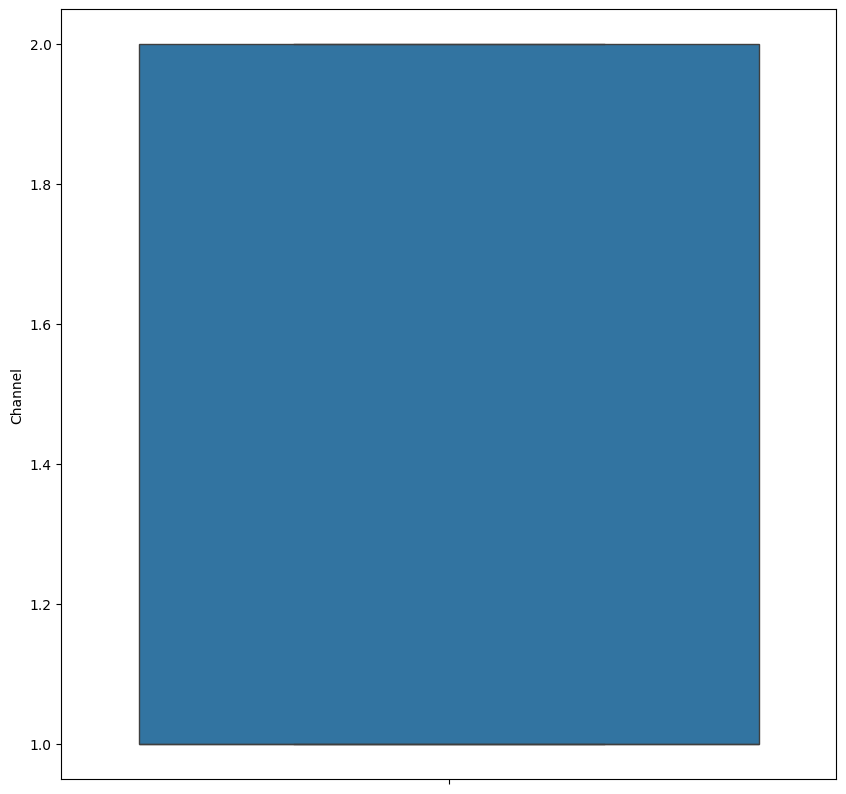

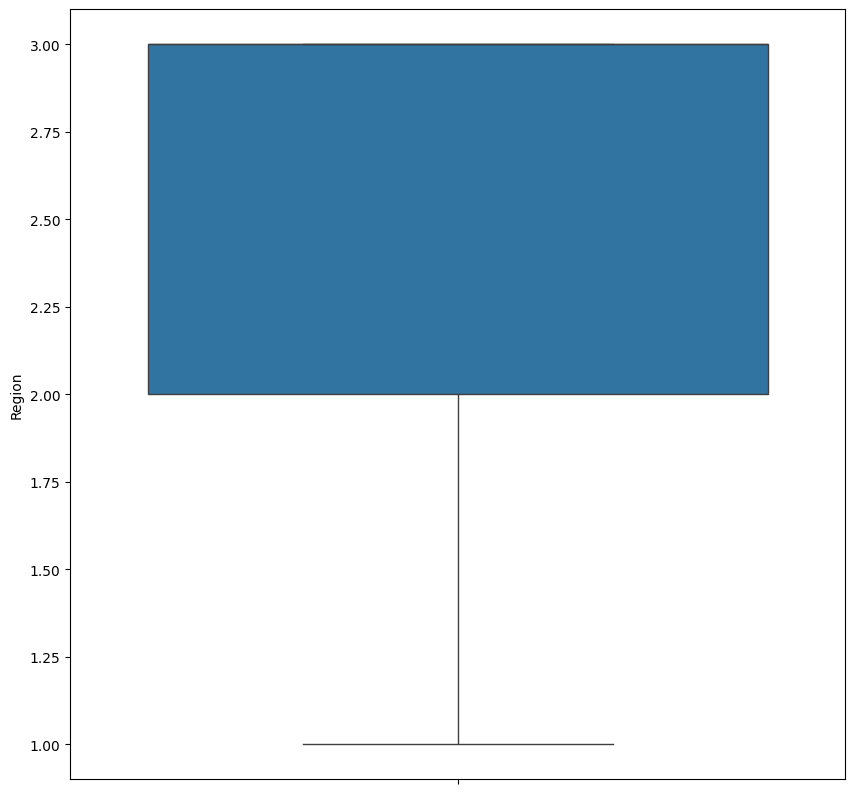

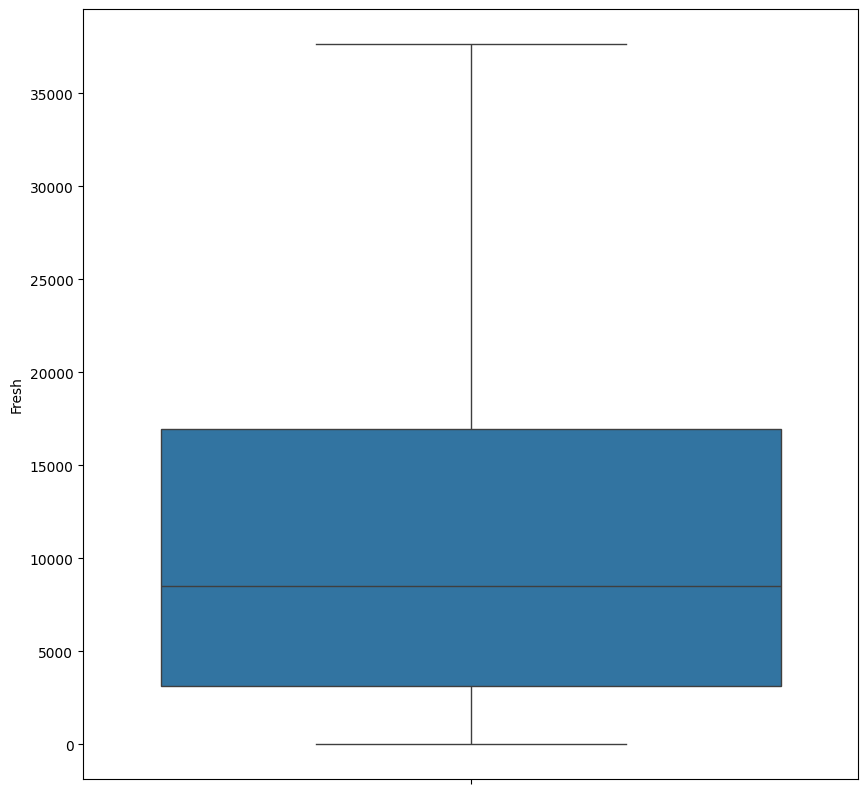

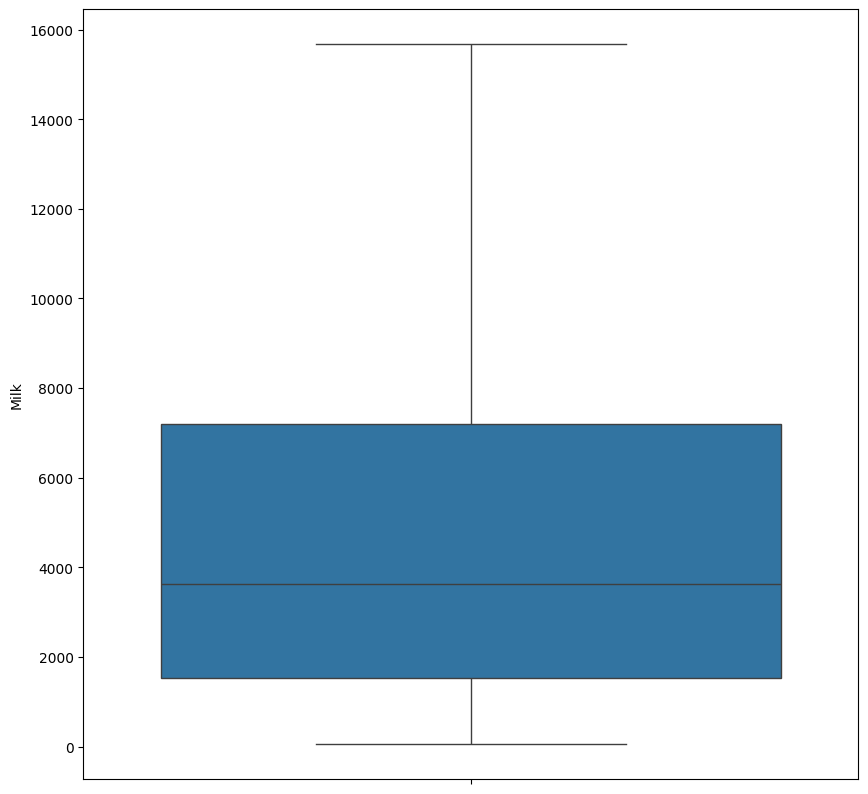

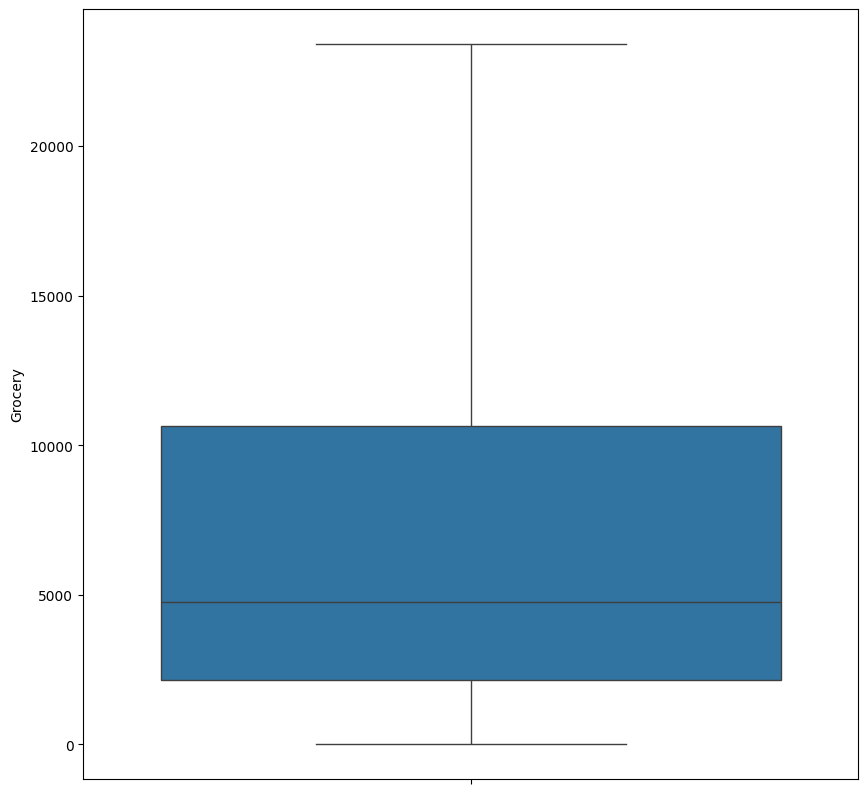

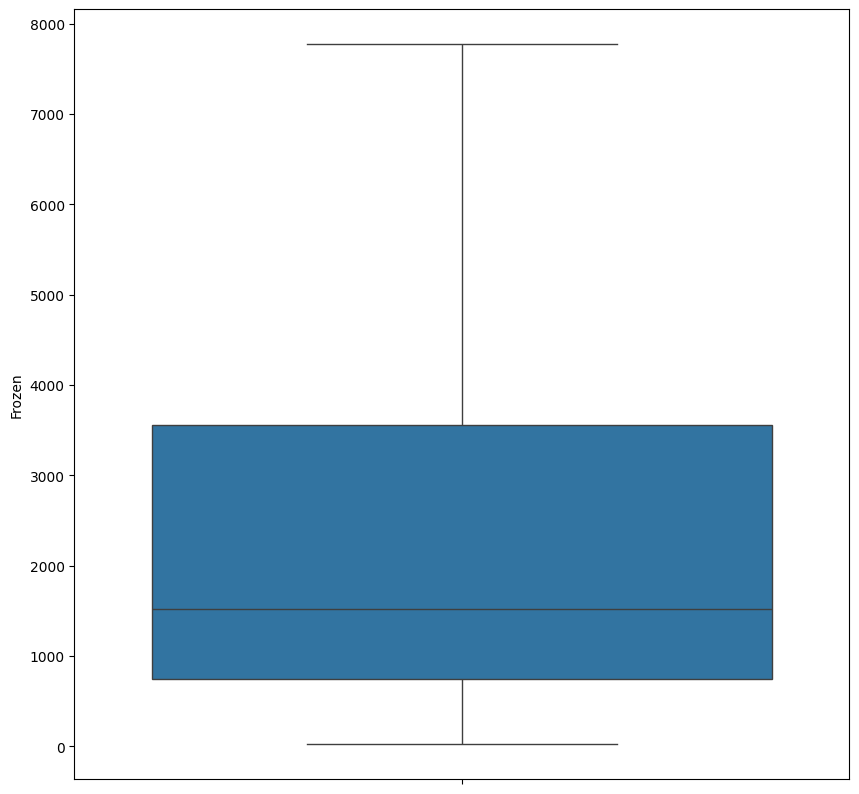

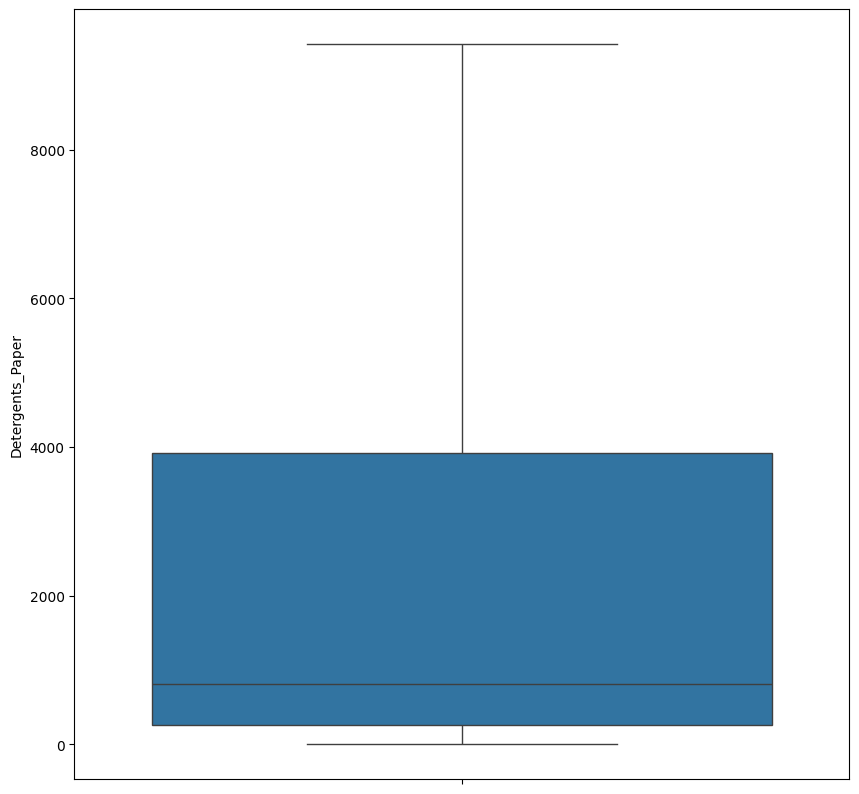

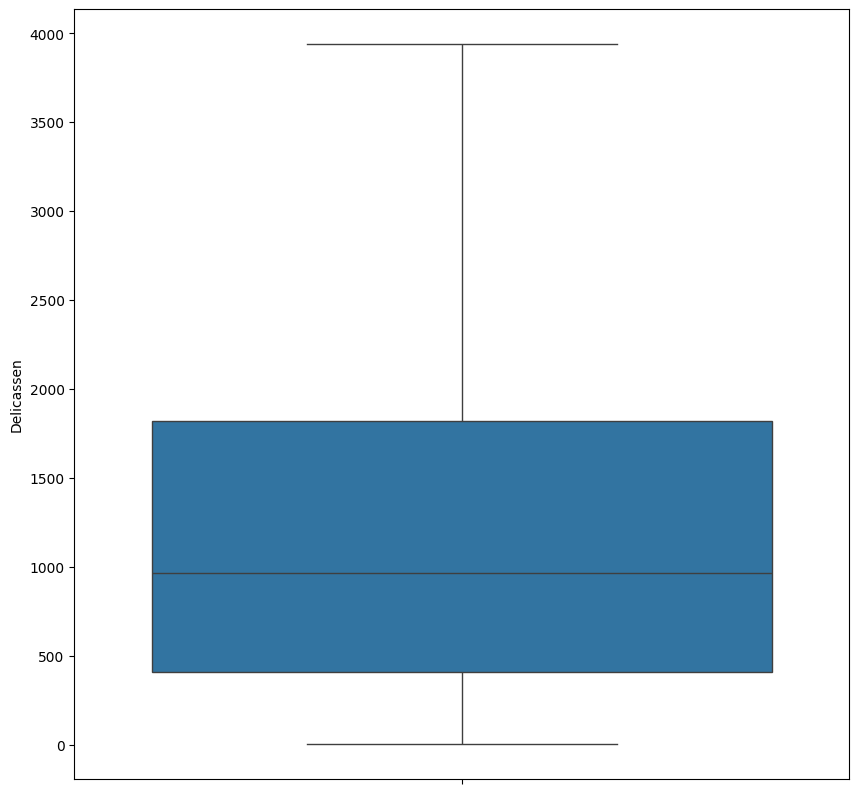

In [10]:
for i in df.columns:
  plt.figure(figsize=(10,10))
  sns.boxplot(df[i])
  plt.show()

In [9]:
for i in df.columns:
  Q3 = df[i].quantile(0.75)
  Q1 = df[i].quantile(0.25)
  IQR = Q3-Q1
  UL = Q3+ 1.5*IQR
  LL = Q1 - 1.5*IQR
  df[i] = df[i].clip(LL,UL)

In [11]:
#Scaling

sc= StandardScaler()

X= sc.fit_transform(df)

In [18]:
X

array([[ 1.44865163,  0.59066829,  0.12857261, ..., -0.95324427,
         0.09579175,  0.06589216],
       [ 1.44865163,  0.59066829, -0.42162716, ..., -0.30973493,
         0.30651872,  0.47075856],
       [ 1.44865163,  0.59066829, -0.49064723, ..., -0.04243744,
         0.38243489,  2.46943983],
       ...,
       [ 1.44865163,  0.59066829,  0.31112285, ..., -0.86054235,
         2.39229863,  0.55487464],
       [-0.69029709,  0.59066829, -0.10466425, ..., -0.61070442,
        -0.75732904,  0.7933576 ],
       [-0.69029709,  0.59066829, -0.84025742, ..., -1.01518413,
        -0.65213577, -1.1228252 ]], shape=(440, 8))

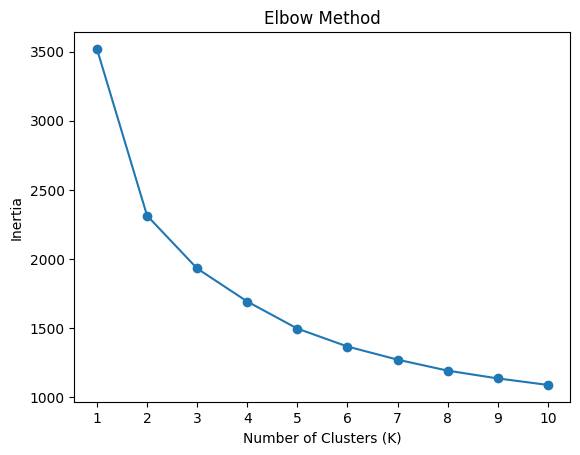

In [14]:
# Find Optimal K using Elbow method

from sklearn.cluster import KMeans

inertia = []

for k in range(1,11):
  kc = KMeans(n_clusters = k, random_state=42,n_init=10)
  kc.fit(X)
  inertia.append(kc.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.show()

In [15]:
k_optimal = 2

kc = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)

kc_labels = kc.fit_predict(X)

print("K-Means cluster counts:")
display(pd.Series(kc_labels, name="cluster").value_counts().sort_index().to_frame("count"))

K-Means cluster counts:


,count
cluster,
0,143
1,297


In [25]:
# DBSCAN

from sklearn.cluster import DBSCAN

ds = DBSCAN(eps = 2, min_samples= 5)

ds_labels = ds.fit_predict(X)

print("DBSCAN cluster counts:")
display(pd.Series(ds_labels, name="cluster").value_counts().sort_index().to_frame("count"))

DBSCAN cluster counts:


,count
cluster,
-1,22
0,130
1,288


In [26]:


comparison = pd.DataFrame({
    "KMeans": kc_labels,
    "DBSCAN": ds_labels
})

print("Cross-tabulation of assigned labels:")
display(pd.crosstab(comparison["KMeans"], comparison["DBSCAN"], margins=True))

Cross-tabulation of assigned labels:


DBSCAN,-1,0,1,All
KMeans,,,,
0,13,126,4,143
1,9,4,284,297
All,22,130,288,440


In [27]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Calculate silhouette score for K-Means
k_means_sil = silhouette_score(X, kc_labels)

# Identify non-noise points in DBSCAN
non_noise = ds_labels != -1
dbscan_non_noise_labels = ds_labels[non_noise]
unique_dbscan_non_noise = np.unique(dbscan_non_noise_labels)

# Calculate silhouette score for DBSCAN (excluding noise, requires at least 2 clusters)
if len(unique_dbscan_non_noise) >= 2:
    dbscan_sil = silhouette_score(X[non_noise], dbscan_non_noise_labels)
else:
    dbscan_sil = np.nan

# Calculate number of clusters and noise points for DBSCAN
n_dbscan_clusters = len(unique_dbscan_non_noise)
n_noise = np.sum(ds_labels == -1)

# Calculate Adjusted Rand Index between K-Means and DBSCAN
ari_between_algorithms = adjusted_rand_score(kc_labels, ds_labels)

# Create the comparison table
metrics = pd.DataFrame({
    "Metric": [
        "Number of clusters",
        "Noise points",
        "Silhouette score",
        "ARI between K-Means and DBSCAN"
    ],
    "K-Means": [k_optimal, 0, k_means_sil, ari_between_algorithms],
    "DBSCAN": [n_dbscan_clusters, n_noise, dbscan_sil, ari_between_algorithms]
})

display(metrics.round(3))

,Metric,K-Means,DBSCAN
0,Number of clusters,2.00,2.000
1,Noise points,0.00,22.000
2,Silhouette score,0.35,0.365
3,ARI between K-Means and DBSCAN,0.84,0.840


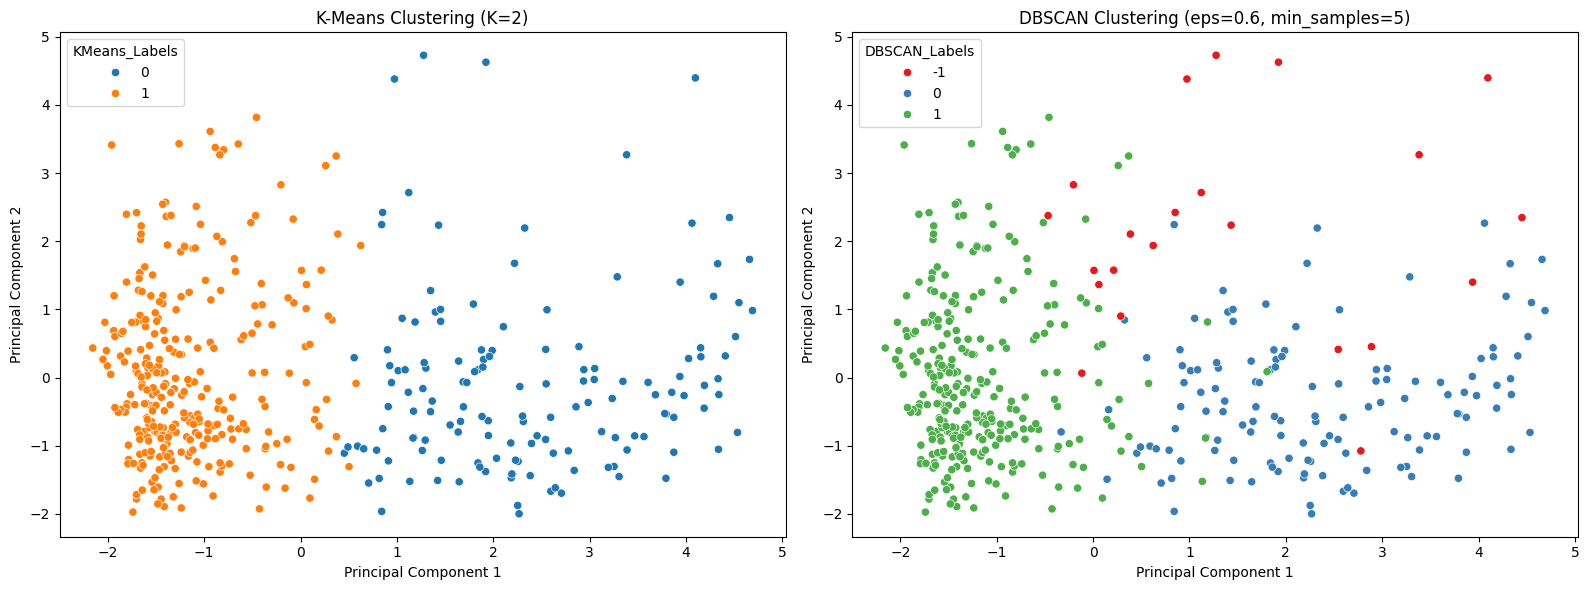

In [28]:
from sklearn.decomposition import PCA

# Reduce the data to 2 dimensions using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Create a visualization dataframe
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['KMeans_Labels'] = kc_labels
pca_df['DBSCAN_Labels'] = ds_labels

# Plot the results side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means Scatter Plot
sns.scatterplot(
    x='PC1', y='PC2',
    hue='KMeans_Labels',
    palette='tab10',
    data=pca_df,
    ax=axes[0],
    legend='full'
)
axes[0].set_title('K-Means Clustering (K=2)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# DBSCAN Scatter Plot (using a different palette to easily identify noise points labeled as -1)
sns.scatterplot(
    x='PC1', y='PC2',
    hue='DBSCAN_Labels',
    palette='Set1',
    data=pca_df,
    ax=axes[1],
    legend='full'
)
axes[1].set_title('DBSCAN Clustering (eps=0.6, min_samples=5)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

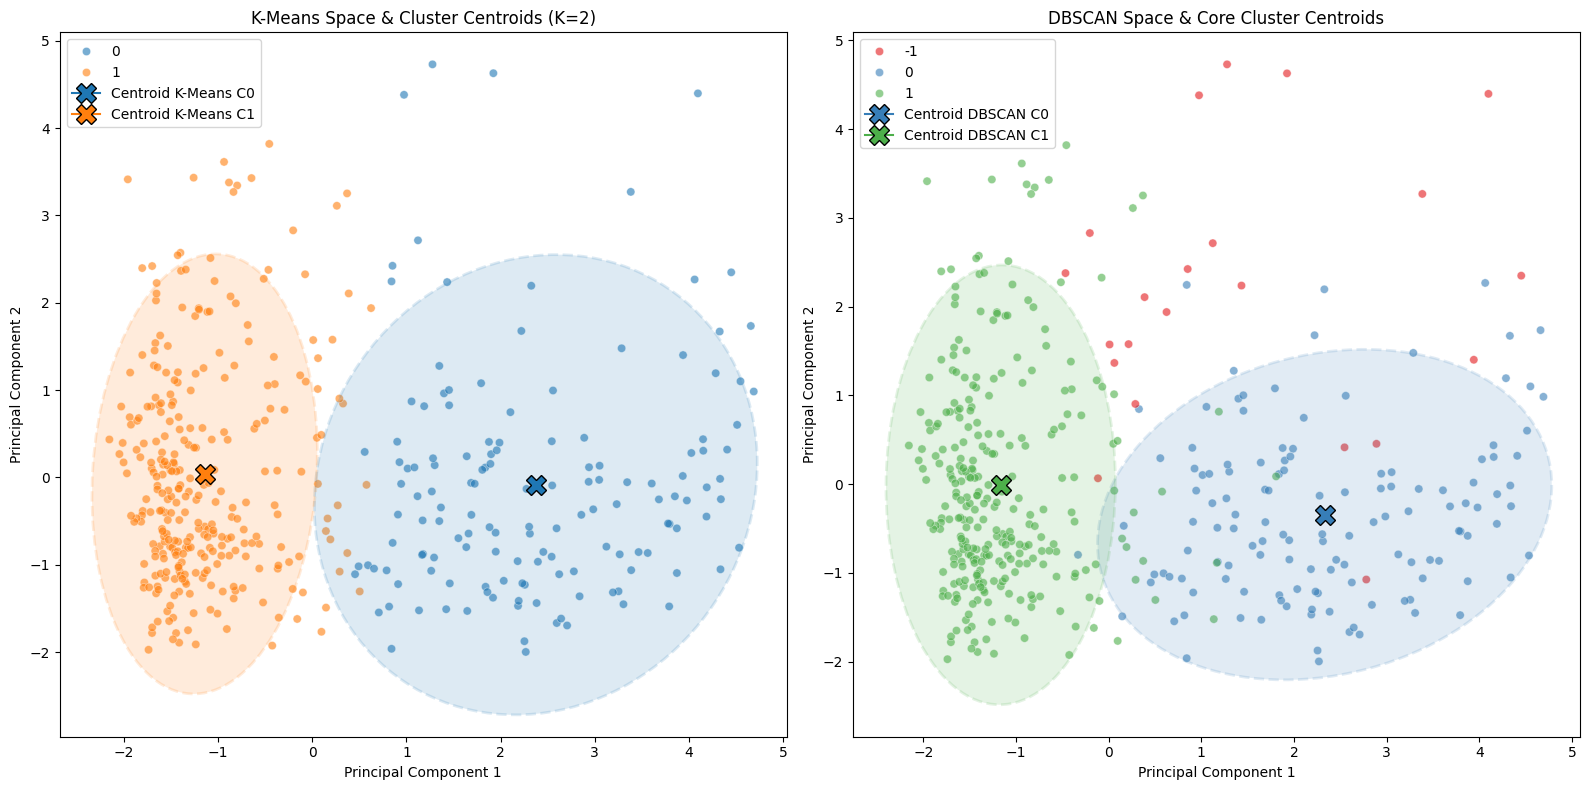

In [30]:
import matplotlib.patches as patches

# Create a new visualization plot with marked spaces/centroids
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Helper function to plot a 2D confidence ellipse for a cluster
def draw_ellipse(points, ax, color, label):
    if len(points) < 3:
        return
    cov = np.cov(points, rowvar=False)
    mean = np.mean(points, axis=0)

    # Eigenvalues and eigenvectors of the covariance matrix
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    # Angle of rotation
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

    # Width and height at 2 standard deviations
    width, height = 2 * 2 * np.sqrt(np.maximum(vals, 0))

    # Draw ellipse
    ell = patches.Ellipse(
        xy=mean, width=width, height=height, angle=theta,
        edgecolor=color, fc=color, alpha=0.15, lw=2, linestyle='--'
    )
    ax.add_patch(ell)
    # Mark the centroid
    ax.plot(mean[0], mean[1], marker='X', color=color, markersize=15, markeredgecolor='black', label=f'Centroid {label}')

# 1. K-Means space
sns.scatterplot(
    x='PC1', y='PC2', hue='KMeans_Labels', palette='tab10',
    data=pca_df, ax=axes[0], alpha=0.6, legend='full'
)

for label in sorted(pca_df['KMeans_Labels'].unique()):
    cluster_points = pca_df[pca_df['KMeans_Labels'] == label][['PC1', 'PC2']].values
    draw_ellipse(cluster_points, axes[0], sns.color_palette('tab10')[label], f"K-Means C{label}")

axes[0].set_title('K-Means Space & Cluster Centroids (K=2)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()

# 2. DBSCAN space
sns.scatterplot(
    x='PC1', y='PC2', hue='DBSCAN_Labels', palette='Set1',
    data=pca_df, ax=axes[1], alpha=0.6, legend='full'
)

# Only draw boundaries/centroids for non-noise DBSCAN clusters
for label in sorted(pca_df['DBSCAN_Labels'].unique()):
    if label == -1:
        continue
    cluster_points = pca_df[pca_df['DBSCAN_Labels'] == label][['PC1', 'PC2']].values
    draw_ellipse(cluster_points, axes[1], sns.color_palette('Set1')[label + 1], f"DBSCAN C{label}")

axes[1].set_title('DBSCAN Space & Core Cluster Centroids')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()

plt.tight_layout()
plt.show()